In [2]:
!pip install networkx

In [3]:
import os
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [4]:
CLEANED_PATH = "../data/processed/cleaned_data.csv"

METADATA_PATH = "../data/processed/graph_metadata.csv"

PROCESSED_DIR = "../data/processed"

OUTPUT_EDGES = "../data/processed/graph_edges.csv"

OUTPUT_NODES = "../data/processed/graph_nodes.csv"

OUTPUT_LABELS = "../data/processed/graph_labels.csv"

In [5]:
for path in [
    CLEANED_PATH,
    METADATA_PATH
]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found:\n{path}")

print("All input files found.")

All input files found.


In [6]:
cleaned_df = pd.read_csv(CLEANED_PATH)

metadata_df = pd.read_csv(METADATA_PATH)

print("Cleaned data shape:", cleaned_df.shape)

print("Metadata shape:", metadata_df.shape)

Cleaned data shape: (286095, 68)
Metadata shape: (286095, 9)


In [7]:
print(metadata_df.columns.tolist())

['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Label', 'Binary_Label']


In [8]:
required_columns = [
    "Source IP",
    "Destination IP",
    "Source Port",
    "Destination Port",
    "Protocol",
    "Timestamp",
    "Binary_Label"
]

for column in required_columns:
    if column not in metadata_df.columns:
        raise KeyError(
            f"Missing column: {column}\n"
            f"Available columns: {metadata_df.columns.tolist()}"
        )

print("All graph columns found.")

All graph columns found.


In [9]:
if len(cleaned_df) != len(metadata_df):
    raise ValueError(
        "Cleaned data and metadata have different row counts."
    )

graph_df = metadata_df.copy()

feature_columns = [
    column
    for column in cleaned_df.columns
    if column != "Binary_Label"
]

for column in feature_columns:
    graph_df[column] = cleaned_df[column].values

print("Combined graph dataset shape:", graph_df.shape)

Combined graph dataset shape: (286095, 76)


In [10]:
graph_df["Source IP"] = (
    graph_df["Source IP"]
    .astype(str)
    .str.strip()
)

graph_df["Destination IP"] = (
    graph_df["Destination IP"]
    .astype(str)
    .str.strip()
)

graph_df = graph_df[
    (graph_df["Source IP"] != "") &
    (graph_df["Destination IP"] != "") &
    (graph_df["Source IP"] != "nan") &
    (graph_df["Destination IP"] != "nan")
].reset_index(drop=True)

print("Rows after IP cleaning:", len(graph_df))

Rows after IP cleaning: 286095


In [11]:
self_loop_count = (
    graph_df["Source IP"] == graph_df["Destination IP"]
).sum()

print("Self-loops found:", self_loop_count)

graph_df = graph_df[
    graph_df["Source IP"] != graph_df["Destination IP"]
].reset_index(drop=True)

print("Rows after removing self-loops:", len(graph_df))

Self-loops found: 0
Rows after removing self-loops: 286095


In [12]:
MAX_FLOWS = 50000

if len(graph_df) > MAX_FLOWS:
    graph_df = graph_df.sample(
        n=MAX_FLOWS,
        random_state=42
    ).reset_index(drop=True)

print("Flows used for graph:", len(graph_df))

Flows used for graph: 50000


In [13]:
source_nodes = graph_df["Source IP"]

destination_nodes = graph_df["Destination IP"]

unique_nodes = sorted(
    set(source_nodes) | set(destination_nodes)
)

print("Number of unique IP nodes:", len(unique_nodes))

Number of unique IP nodes: 3001


In [14]:
node_to_id = {
    ip: index
    for index, ip in enumerate(unique_nodes)
}

id_to_node = {
    index: ip
    for ip, index in node_to_id.items()
}

print("Example node mapping:")
print(list(node_to_id.items())[:10])

Example node mapping:
[('101.37.178.168', 0), ('103.23.4.38', 1), ('103.235.252.17', 2), ('103.235.252.232', 3), ('103.235.46.39', 4), ('103.243.172.110', 5), ('103.37.152.74', 6), ('103.43.91.7', 7), ('103.6.0.15', 8), ('103.6.0.2', 9)]


In [15]:
edges = pd.DataFrame({
    "source": graph_df["Source IP"].map(node_to_id),
    "target": graph_df["Destination IP"].map(node_to_id),
    "source_ip": graph_df["Source IP"],
    "destination_ip": graph_df["Destination IP"],
    "source_port": graph_df["Source Port"],
    "destination_port": graph_df["Destination Port"],
    "protocol": graph_df["Protocol"],
    "timestamp": graph_df["Timestamp"],
    "label": graph_df["Binary_Label"]
})

print("Edge table shape:", edges.shape)

edges.head()

Edge table shape: (50000, 9)


,source,target,source_ip,destination_ip,source_port,destination_port,protocol,timestamp,label
0,990,994,192.168.10.17,192.168.10.3,50251,53,17,7/7/2017 1:48,0
1,639,996,172.16.0.1,192.168.10.50,42254,32777,6,7/7/2017 3:08,1
2,639,996,172.16.0.1,192.168.10.50,52754,30951,6,7/7/2017 2:55,1
3,639,996,172.16.0.1,192.168.10.50,43109,902,6,7/7/2017 2:51,1
4,639,996,172.16.0.1,192.168.10.50,37796,500,6,7/7/2017 2:52,1


In [16]:
nodes = pd.DataFrame({
    "node_id": range(len(unique_nodes)),
    "ip_address": unique_nodes
})

print("Node table shape:", nodes.shape)

nodes.head()

Node table shape: (3001, 2)


,node_id,ip_address
0,0,101.37.178.168
1,1,103.23.4.38
2,2,103.235.252.17
3,3,103.235.252.232
4,4,103.235.46.39


In [17]:
out_degree = edges.groupby("source").size()

in_degree = edges.groupby("target").size()

nodes["out_degree"] = (
    nodes["node_id"]
    .map(out_degree)
    .fillna(0)
    .astype(int)
)

nodes["in_degree"] = (
    nodes["node_id"]
    .map(in_degree)
    .fillna(0)
    .astype(int)
)

nodes["total_degree"] = (
    nodes["in_degree"] +
    nodes["out_degree"]
)

nodes.head()

,node_id,ip_address,out_degree,in_degree,total_degree
0,0,101.37.178.168,0,2,2
1,1,103.23.4.38,1,0,1
2,2,103.235.252.17,0,1,1
3,3,103.235.252.232,1,0,1
4,4,103.235.46.39,1,0,1


In [18]:
source_attack_count = (
    edges[edges["label"] == 1]
    .groupby("source")
    .size()
)

target_attack_count = (
    edges[edges["label"] == 1]
    .groupby("target")
    .size()
)

nodes["source_attack_count"] = (
    nodes["node_id"]
    .map(source_attack_count)
    .fillna(0)
    .astype(int)
)

nodes["target_attack_count"] = (
    nodes["node_id"]
    .map(target_attack_count)
    .fillna(0)
    .astype(int)
)

nodes["total_attack_count"] = (
    nodes["source_attack_count"] +
    nodes["target_attack_count"]
)

nodes.head()

,node_id,ip_address,out_degree,in_degree,total_degree,source_attack_count,target_attack_count,total_attack_count
0,0,101.37.178.168,0,2,2,0,0,0
1,1,103.23.4.38,1,0,1,0,0,0
2,2,103.235.252.17,0,1,1,0,0,0
3,3,103.235.252.232,1,0,1,0,0,0
4,4,103.235.46.39,1,0,1,0,0,0


In [19]:
attack_nodes = set(
    edges.loc[edges["label"] == 1, "source"]
) | set(
    edges.loc[edges["label"] == 1, "target"]
)

nodes["node_label"] = (
    nodes["node_id"]
    .isin(attack_nodes)
    .astype(int)
)

print("Node label distribution:")
print(nodes["node_label"].value_counts())

Node label distribution:
node_label
0    2999
1       2
Name: count, dtype: int64


In [20]:
G = nx.DiGraph()

for _, row in nodes.iterrows():
    G.add_node(
        int(row["node_id"]),
        ip_address=row["ip_address"],
        node_label=int(row["node_label"])
    )

for _, row in edges.iterrows():
    G.add_edge(
        int(row["source"]),
        int(row["target"]),
        label=int(row["label"]),
        protocol=row["protocol"]
    )

print("Number of graph nodes:", G.number_of_nodes())

print("Number of graph edges:", G.number_of_edges())

Number of graph nodes: 3001
Number of graph edges: 5952


In [21]:
print("Graph type:", type(G).__name__)

print("Number of nodes:", G.number_of_nodes())

print("Number of edges:", G.number_of_edges())

print("Density:", nx.density(G))

print("Is directed:", G.is_directed())

Graph type: DiGraph
Number of nodes: 3001
Number of edges: 5952
Density: 0.0006611129623458847
Is directed: True


In [22]:
print("Normal edges:", (edges["label"] == 0).sum())

print("Attack edges:", (edges["label"] == 1).sum())

Normal edges: 22385
Attack edges: 27615


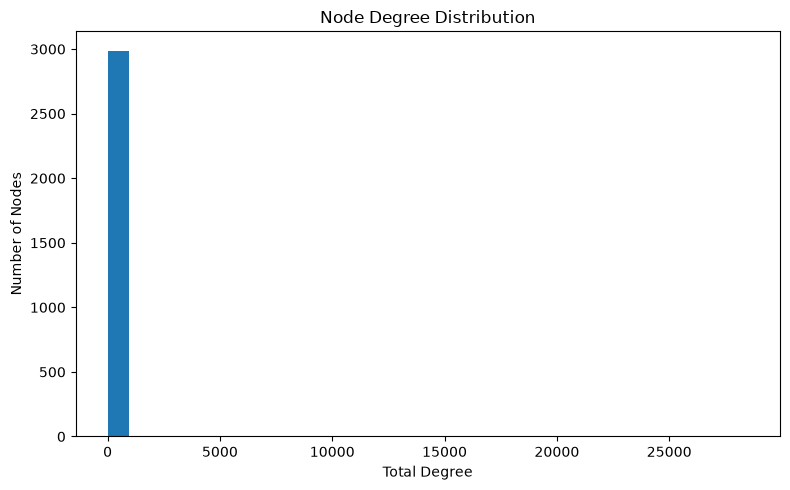

In [23]:
plt.figure(figsize=(8, 5))

nodes["total_degree"].plot(
    kind="hist",
    bins=30
)

plt.title("Node Degree Distribution")
plt.xlabel("Total Degree")
plt.ylabel("Number of Nodes")

plt.tight_layout()

plt.show()

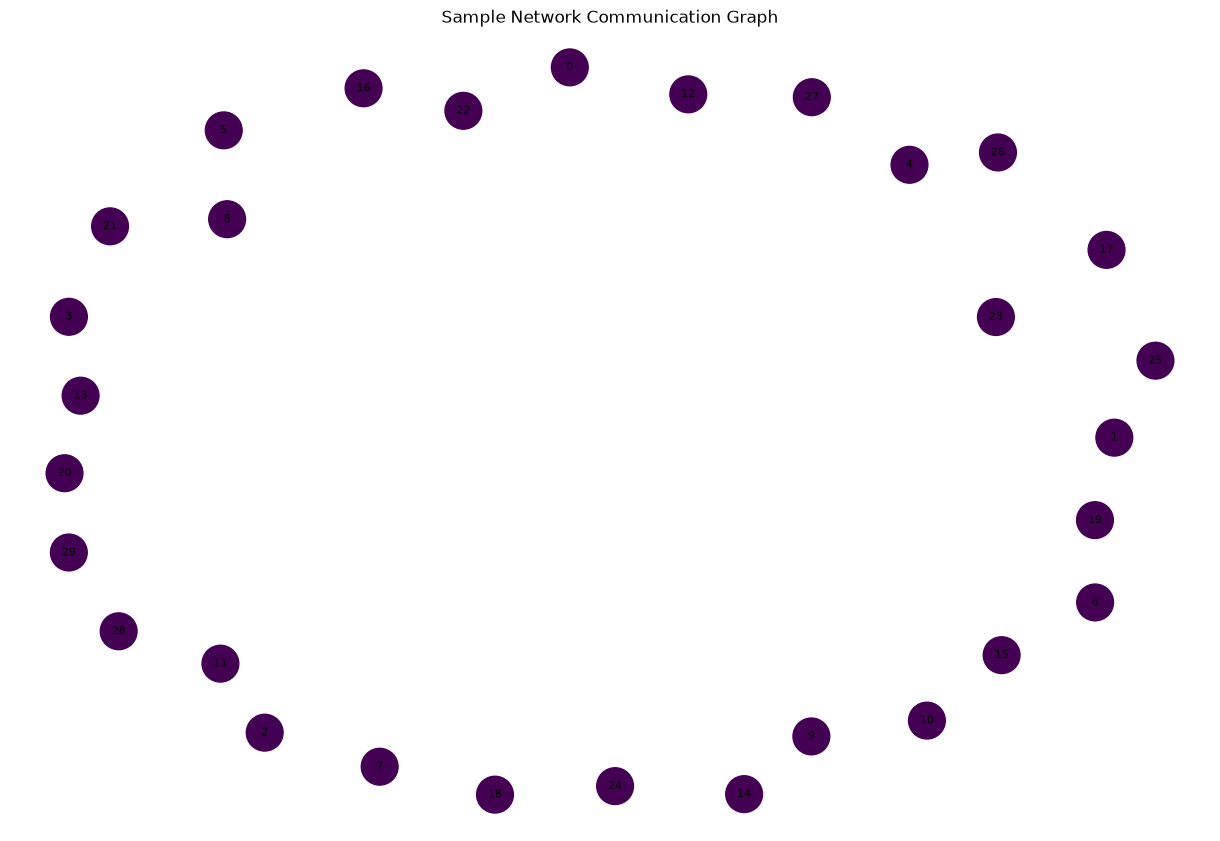

In [24]:
SAMPLE_NODES = min(30, G.number_of_nodes())

sample_node_ids = list(G.nodes())[:SAMPLE_NODES]

G_sample = G.subgraph(sample_node_ids).copy()

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_sample,
    seed=42
)

node_colors = [
    G_sample.nodes[node]["node_label"]
    for node in G_sample.nodes()
]

nx.draw(
    G_sample,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=700,
    arrows=True,
    font_size=8
)

plt.title("Sample Network Communication Graph")

plt.show()

In [25]:
edges.to_csv(
    OUTPUT_EDGES,
    index=False
)

print(f"Saved: {OUTPUT_EDGES}")

Saved: ../data/processed/graph_edges.csv


In [26]:
nodes.to_csv(
    OUTPUT_NODES,
    index=False
)

print(f"Saved: {OUTPUT_NODES}")

Saved: ../data/processed/graph_nodes.csv


In [27]:
graph_labels = edges[
    [
        "source",
        "target",
        "label"
    ]
].copy()

graph_labels.to_csv(
    OUTPUT_LABELS,
    index=False
)

print(f"Saved: {OUTPUT_LABELS}")

Saved: ../data/processed/graph_labels.csv


In [28]:
print("========== DAY 3 COMPLETE ==========")

print("Nodes:", len(nodes))

print("Edges:", len(edges))

print("Normal edges:", (edges["label"] == 0).sum())

print("Attack edges:", (edges["label"] == 1).sum())

print("Saved files:")

print("1. data/processed/graph_edges.csv")

print("2. data/processed/graph_nodes.csv")

print("3. data/processed/graph_labels.csv")

========== DAY 3 COMPLETE ==========
Nodes: 3001
Edges: 50000
Normal edges: 22385
Attack edges: 27615
Saved files:
1. data/processed/graph_edges.csv
2. data/processed/graph_nodes.csv
3. data/processed/graph_labels.csv
